## Import Libraries & Create a Fresh Dataset

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification

sns.set_theme(style="whitegrid")

# Generate a fresh binary classification dataset (100 rows, 3 features)
X, y = make_classification(
    n_samples=100, n_features=3, n_informative=3, n_redundant=0, random_state=42
)

print("Input Data Shape (Samples, Features):", X.shape)
print("Target Labels Shape:", y.shape)
print("First Sample Features:", X[0])
print("First Sample True Label:", y[0])

Input Data Shape (Samples, Features): (100, 3)
Target Labels Shape: (100,)
First Sample Features: [-0.0550468  -0.07689964  1.01423611]
First Sample True Label: 1


## Manual Forward Propagation in Pure NumPy

In [2]:
# 1. Define Activation Functions
def relu(z):
    return np.maximum(0, z)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# 2. Initialize Weights and Biases
np.random.seed(42)
W1 = np.random.randn(3, 4) * 0.5  # Weights: Input (3) -> Hidden (4)
b1 = np.zeros((1, 4))  # Bias for 4 hidden neurons

W2 = np.random.randn(4, 1) * 0.5  # Weights: Hidden (4) -> Output (1)
b2 = np.zeros((1, 1))  # Bias for 1 output neuron

# 3. Execute Forward Propagation
# Layer 1: Input -> Hidden
Z1 = np.dot(X, W1) + b1
A1 = relu(Z1)

# Layer 2: Hidden -> Output
Z2 = np.dot(A1, W2) + b2
y_pred = sigmoid(Z2)

print("Hidden Layer Output Shape (A1):", A1.shape)
print("Final Predictions Shape (y_pred):", y_pred.shape)
print("\nFirst 5 Predicted Probabilities:\n", y_pred[:5].flatten())

Hidden Layer Output Shape (A1): (100, 4)
Final Predictions Shape (y_pred): (100, 1)

First 5 Predicted Probabilities:
 [0.43156605 0.38323314 0.5        0.32803069 0.45090546]


## Verify with TensorFlow / Keras

In [3]:
# Build identical Keras model
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(3,)),
        tf.keras.layers.Dense(4, activation="relu", name="hidden_layer"),
        tf.keras.layers.Dense(1, activation="sigmoid", name="output_layer"),
    ]
)

# Copy our manual NumPy weights into the Keras layers
model.get_layer("hidden_layer").set_weights([W1, b1.flatten()])
model.get_layer("output_layer").set_weights([W2, b2.flatten()])

# Run Keras forward pass
keras_pred = model.predict(X, verbose=0)

# Check if NumPy and Keras outputs match
difference = np.max(np.abs(y_pred - keras_pred))
print(f"Max difference between NumPy and Keras forward pass: {difference:.10f}")

Max difference between NumPy and Keras forward pass: 0.0000000963



## Visualize Forward Propagation Data Flow


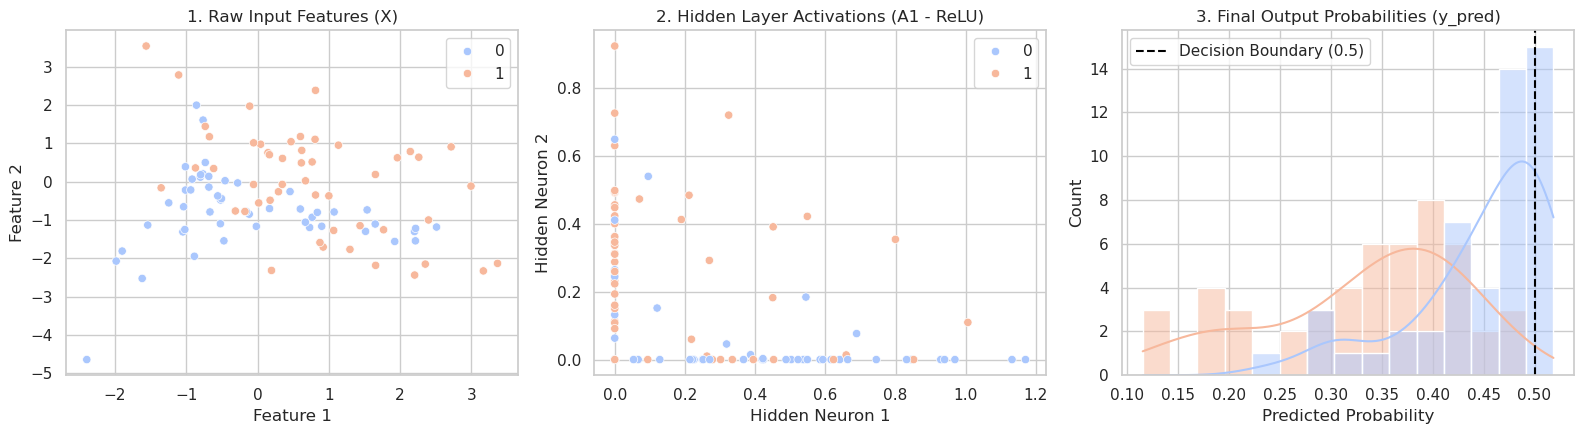

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Raw Input Data (Feature 1 vs Feature 2)
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette="coolwarm", ax=axes[0])
axes[0].set_title("1. Raw Input Features (X)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Plot 2: Hidden Layer Activations (Neuron 1 vs Neuron 2 after ReLU)
sns.scatterplot(x=A1[:, 0], y=A1[:, 1], hue=y, palette="coolwarm", ax=axes[1])
axes[1].set_title("2. Hidden Layer Activations (A1 - ReLU)")
axes[1].set_xlabel("Hidden Neuron 1")
axes[1].set_ylabel("Hidden Neuron 2")

# Plot 3: Final Output Probabilities (Sigmoid)
sns.histplot(
    x=y_pred.flatten(), hue=y, bins=15, palette="coolwarm", ax=axes[2], kde=True
)
axes[2].axvline(0.5, color="black", linestyle="--", label="Decision Boundary (0.5)")
axes[2].set_title("3. Final Output Probabilities (y_pred)")
axes[2].set_xlabel("Predicted Probability")
axes[2].legend()

plt.tight_layout()
plt.show()